# Environment Setup and Library Imports

In [9]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import os
from sklearn.decomposition import PCA
from transformers import CLIPModel
from tqdm import tqdm
from IPython.display import Image, display
import torch.nn.functional as F
import gc

from src.model import CLIPForFlickr8k
from src.dataset import create_dataloaders
from src.train import train
from src.evaluate import (load_captions, prepare_fixed_captions, evaluate_i2t_recall_at_k, evaluate_t2i_recall_at_k)
from src.inference import run_inference


# Check GPU availability
print(f"CUDA Available: {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")

CUDA Available: True
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM: 8.6 GB


#  Data Loading and Preprocessing Configuration

In [10]:
# Use correct paths (without data/ prefix)
IMAGE_DIR = os.path.abspath('Flickr8k/Images')
CAPTIONS_FILE = os.path.abspath('Flickr8k/captions.txt')
MODEL_PATH = os.path.abspath('models/clip-vit-base-patch32')


# Load CLIP model
device = 'cuda' if torch.cuda.is_available() else 'cpu'
model = CLIPForFlickr8k(clip_model_name=MODEL_PATH, device=device)
processor = model.processor

# Create dataloaders
print("\nCreating dataloaders...")
train_loader, val_loader, test_loader = create_dataloaders(IMAGE_DIR, CAPTIONS_FILE, processor, batch_size=32)


# Show sample batch
batch = next(iter(train_loader))
print(f"\n Sample batch:")
print(f"  Image shape: {batch['image'].shape}")
print(f"  Text shape: {batch['text'].shape}")
print(f"  Caption example: {batch['caption'][0][:100]}...")

Loading CLIP from: /home/mrrobot/my_first_pytorch/models/clip-vit-base-patch32


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Trainable: 10,895,616 / 151,277,313 (7.2%)

Creating dataloaders...
train split: 6472 images (augment=on)
val split: 809 images (augment=off)
test split: 810 images (augment=off)

 Sample batch:
  Image shape: torch.Size([32, 3, 224, 224])
  Text shape: torch.Size([32, 24])
  Caption example: A child stoops to pick up a watermelon from a large pile of them ....


#  Dataset Sample Visualization

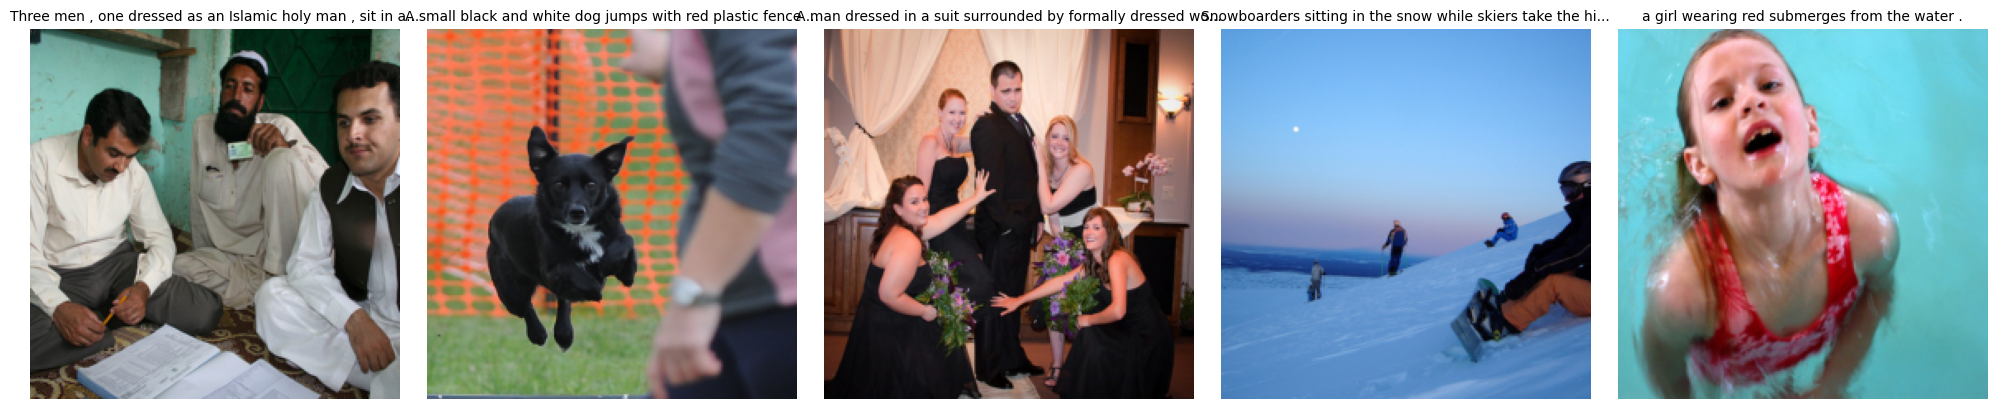

In [11]:
os.makedirs('outputs/results', exist_ok=True)

mean = processor.image_processor.image_mean  
std = processor.image_processor.image_std   

def denormalize_image(tensor):
    tensor = tensor * torch.tensor(std).view(3, 1, 1) + torch.tensor(mean).view(3, 1, 1)
    return tensor.clamp(0, 1)

def show_samples(dataloader, num_samples=5):
    """Display sample images with their captions"""
    batch = next(iter(dataloader))
    fig, axes = plt.subplots(1, num_samples, figsize=(20, 4))
    
    for i in range(num_samples):
        # Denormalize image tensor
        img_tensor = denormalize_image(batch['image'][i])
        img = img_tensor.permute(1, 2, 0).cpu().numpy()
        
        axes[i].imshow(img)
        # Truncate long captions for display
        caption = batch['caption'][i]
        if len(caption) > 60:
            caption = caption[:57] + '...'
        axes[i].set_title(caption, fontsize=10)
        axes[i].axis('off')
    
    plt.tight_layout()
    plt.savefig('outputs/results/dataset_samples.png', dpi=150, bbox_inches='tight')
    plt.show()


show_samples(train_loader)

# Fine-tuning on Flickr8k Dataset

Starting Fine-tuning
--------------------------------------------------
Optimizing 10,895,616 parameters

Epoch 1/30


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 14.49it/s]


Train Loss: 0.5638, Val Loss: 0.3191, LR: 9.98e-06
Best model saved

Epoch 2/30


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 16.02it/s]


Train Loss: 0.2772, Val Loss: 0.2707, LR: 9.90e-06
Best model saved

Epoch 3/30


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 15.94it/s]


... (51 outputs left out)

Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 16.07it/s]


Train Loss: 0.1103, Val Loss: 0.1980, LR: 1.02e-06

Epoch 30/30


Validation: 100%|███████████████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 16.10it/s]


Train Loss: 0.1015, Val Loss: 0.1971, LR: 1.00e-06
Best model saved

------------------------------------------------------------
Loading best model weights...
Loaded from epoch 30, Val Loss: 0.1971
------------------------------------------------------------


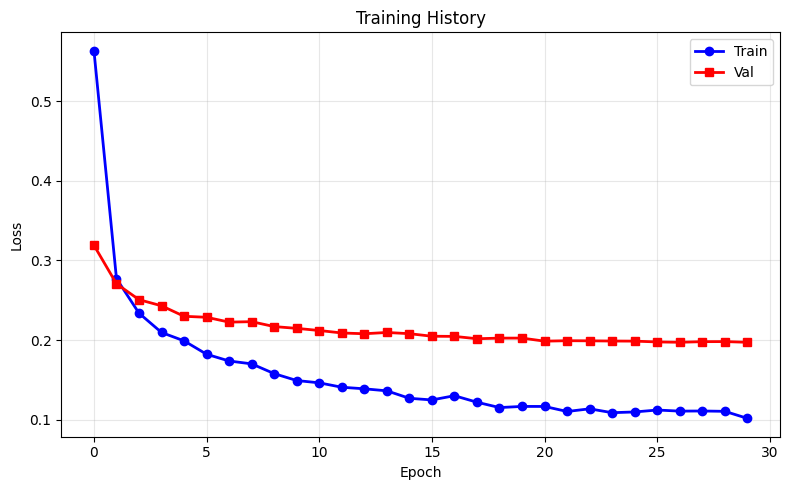


 Best: Epoch 30, Val Loss: 0.1971


In [4]:
os.makedirs('outputs/checkpoints', exist_ok=True)

print("Starting Fine-tuning")
print("-" * 50)

train_losses, val_losses = train(
    model, train_loader, val_loader,
    num_epochs=30,
    lr=1e-5,
    device=device
)

# Plot
plt.figure(figsize=(8, 5))
plt.plot(train_losses, 'b-o', label='Train', linewidth=2)
plt.plot(val_losses, 'r-s', label='Val', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training History')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('outputs/results/training_history.png', dpi=150)
plt.show()

best_epoch = val_losses.index(min(val_losses)) + 1
print(f"\n Best: Epoch {best_epoch}, Val Loss: {min(val_losses):.4f}")

# Comprehensive Retrieval Evaluation

In [12]:
# Load best model
checkpoint = torch.load(
    'outputs/checkpoints/best_model.pth',
    map_location=device,
    weights_only=False,
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
print(f"Loaded from epoch {checkpoint['epoch']+1}, Val Loss: {checkpoint['val_loss']:.4f}")

# Load captions
image_to_captions, all_captions_pool = load_captions(CAPTIONS_FILE)
print(f"Loaded captions for {len(image_to_captions)} images")

# Prepare fixed random captions
test_image_names = test_loader.dataset.images
fixed_random_captions = prepare_fixed_captions(
    all_captions_pool, test_image_names
)

# Image-to-Text evaluation
print("\n" + "-"*60)
print("IMAGE-TO-TEXT RETRIEVAL")
print("-"*60)
i2t_results, total_i2t = evaluate_i2t_recall_at_k(
    model, test_loader, image_to_captions, fixed_random_captions, processor, device
)
print(f"Queries evaluated (images): {total_i2t}")
print(f"Recall@1:  {i2t_results[1]:.2f}%")
print(f"Recall@5:  {i2t_results[5]:.2f}%")
print(f"Recall@10: {i2t_results[10]:.2f}%")

# Text-to-Image evaluation
print("\n" + "-"*60)
print("TEXT-TO-IMAGE RETRIEVAL")
print("-"*60)
t2i_results, total_t2i = evaluate_t2i_recall_at_k(
    model, test_loader, image_to_captions, processor, device
)
print(f"Queries evaluated (captions): {total_t2i}")
print(f"Recall@1:  {t2i_results[1]:.2f}%")
print(f"Recall@5:  {t2i_results[5]:.2f}%")
print(f"Recall@10: {t2i_results[10]:.2f}%")

Loaded from epoch 30, Val Loss: 0.1971
[load_captions] 8091 images, 40453 captions (min_caption_len=5)
Loaded captions for 8091 images
[prepare_fixed_captions] restrict_to_test=False | negatives/img: min=95, max=95, mean=95.0

------------------------------------------------------------
IMAGE-TO-TEXT RETRIEVAL
------------------------------------------------------------


Image-to-Text: 100%|████████████████████████████████████████████████████████████████████| 26/26 [01:06<00:00,  2.57s/it]


Queries evaluated (images): 810
Recall@1:  97.90%
Recall@5:  100.00%
Recall@10: 100.00%

------------------------------------------------------------
TEXT-TO-IMAGE RETRIEVAL
------------------------------------------------------------
Pre-encoding all test images...


Encoding images: 100%|██████████████████████████████████████████████████████████████████| 26/26 [00:02<00:00, 10.30it/s]


Encoded 810 images


Text-to-Image: 100%|██████████████████████████████████████████████████████████████████| 810/810 [00:34<00:00, 23.77it/s]

Queries evaluated (captions): 4049
Recall@1:  67.13%
Recall@5:  91.48%
Recall@10: 96.27%


#  Model Inference

Loading best model...
Loaded from epoch 30, Val loss: 0.1971
[load_captions] 8091 images, 40453 captions (min_caption_len=5)

------------------------------------------------------------
Test Image: 987907964_5a06a63609.jpg
------------------------------------------------------------
Ground Truth Captions:
  • one brown and white dog chasing a black and white dog through the grass
  • The two dogs are running through the grass .
  • Two cocker spaniels running through the grass .
  • Two dogs are running through a green yard
  • Two dogs are running through the grass near a house and trees .

Searching among 100 captions (from full dataset)...

------------------------------------------------------------
Top-5 Retrieved Captions:
------------------------------------------------------------
  1. [8.7] (30.5%) The two dogs are running through the grass .  GROUND TRUTH
  2. [8.6] (27.7%) Two dogs are running through a green yard  GROUND TRUTH
  3. [8.2] (19.2%) Two dogs are running throug

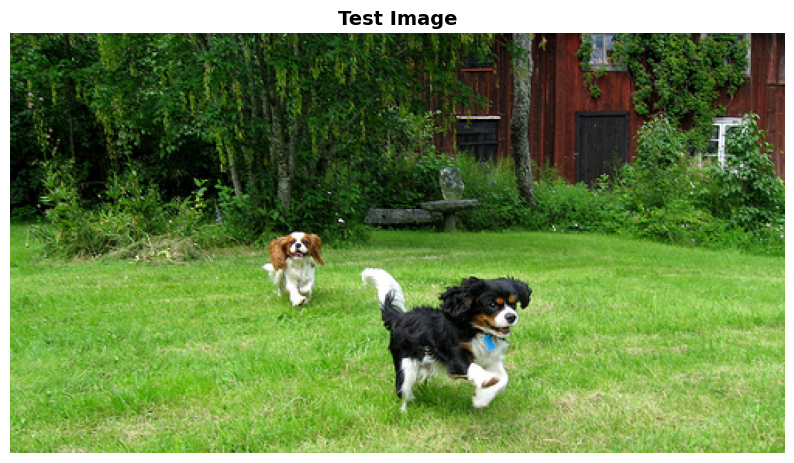

In [13]:
top5, captions, ground_truth = run_inference(
    model=model,
    test_loader=test_loader,
    IMAGE_DIR=IMAGE_DIR,
    CAPTIONS_FILE=CAPTIONS_FILE,
    device=device,
)

display(Image('outputs/inference/i2t_query_image.png'))

#  Embedding Space Visualization with PCA

Collected 160 pairs
Feature dimension: 512


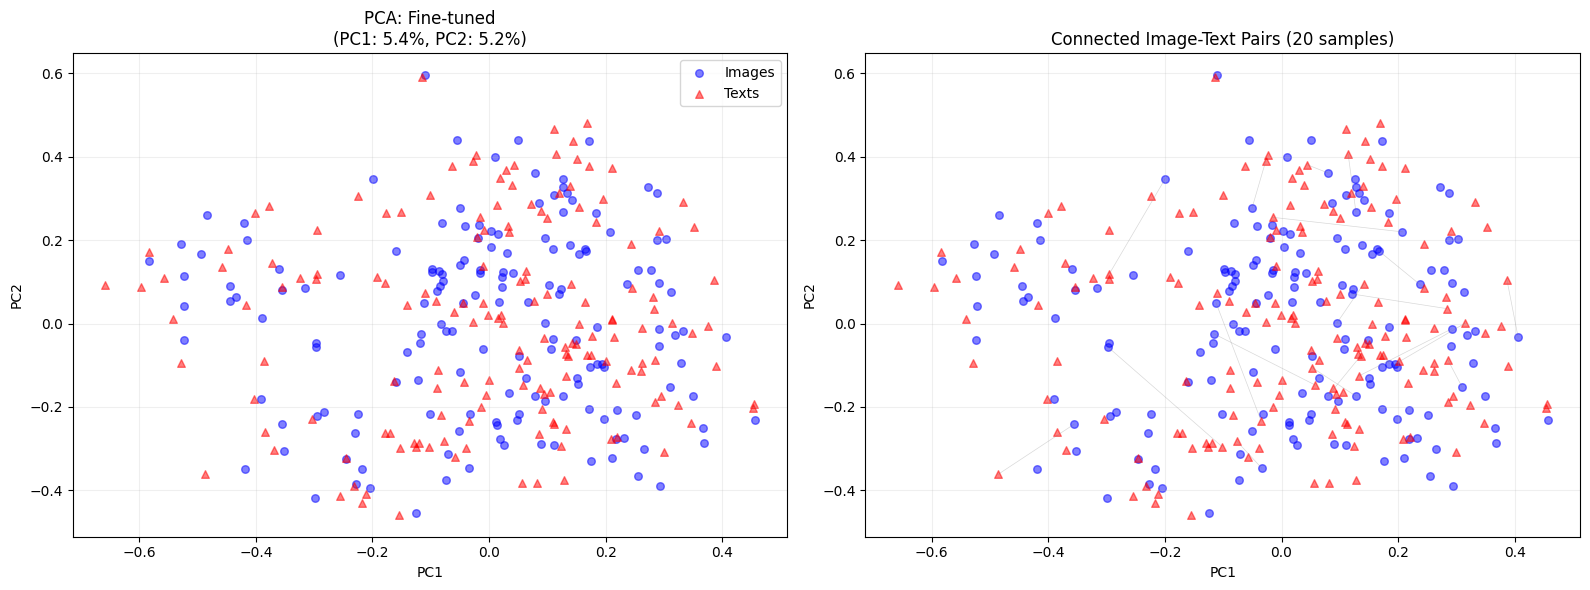


EMBEDDING ANALYSIS - Fine-tuned
--------------------------------------------------
PCA Variance: PC1=5.4%, PC2=5.2%
Total 2D variance: 10.6%
Modality Gap (512D): 0.1563
Avg pair distance (512D): 0.9059 ± 0.1038


In [14]:
os.makedirs('outputs/results', exist_ok=True)

# Loading fine-tuned model for visualization
checkpoint = torch.load(
    'outputs/checkpoints/best_model.pth',
    map_location=device,
    weights_only=False,
)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
model_type = "Fine-tuned"

# Collect embeddings
image_features_list = []
text_features_list = []

with torch.no_grad():
    for i, batch in enumerate(test_loader):
        if i >= 5:
            break

        images = batch['image'].to(device)
        texts = batch['text'].to(device)
        attention_mask = batch['attention_mask'].to(device)

        # Wrapper model forward
        _, _, img_feat, txt_feat = model(images, texts, attention_mask=attention_mask)

        image_features_list.append(img_feat.cpu().numpy())
        text_features_list.append(txt_feat.cpu().numpy())

image_features = np.vstack(image_features_list)
text_features = np.vstack(text_features_list)
combined = np.vstack([image_features, text_features])

n = len(image_features)
print(f"Collected {n} pairs")
print(f"Feature dimension: {image_features.shape[1]}")

# PCA (for visualization only)
pca = PCA(n_components=2)
reduced = pca.fit_transform(combined)
images_pca = reduced[:n]
texts_pca = reduced[n:]

# Plot
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# All points
axes[0].scatter(images_pca[:, 0], images_pca[:, 1], c='blue', label='Images', alpha=0.5, s=30)
axes[0].scatter(texts_pca[:, 0], texts_pca[:, 1], c='red', label='Texts', alpha=0.5, s=30, marker='^')
axes[0].set_title(f'PCA: {model_type}\n(PC1: {pca.explained_variance_ratio_[0]:.1%}, PC2: {pca.explained_variance_ratio_[1]:.1%})')
axes[0].set_xlabel('PC1')
axes[0].set_ylabel('PC2')
axes[0].legend()
axes[0].grid(True, alpha=0.2)

# Connected pairs (deterministic)
rng = np.random.default_rng(42)
sample_idx = rng.choice(n, min(20, n), replace=False)
for idx in sample_idx:
    axes[1].plot(
        [images_pca[idx, 0], texts_pca[idx, 0]],
        [images_pca[idx, 1], texts_pca[idx, 1]],
        'gray', alpha=0.3, linewidth=0.5,
    )
axes[1].scatter(images_pca[:, 0], images_pca[:, 1], c='blue', alpha=0.5, s=30)
axes[1].scatter(texts_pca[:, 0], texts_pca[:, 1], c='red', alpha=0.5, s=30, marker='^')
axes[1].set_title('Connected Image-Text Pairs (20 samples)')
axes[1].set_xlabel('PC1')
axes[1].set_ylabel('PC2')
axes[1].grid(True, alpha=0.2)

plt.tight_layout()
plt.savefig('outputs/results/embeddings_pca.png', dpi=150)
plt.show()

# Statistics in the ORIGINAL 512D space
pair_distances_512 = np.linalg.norm(image_features - text_features, axis=1)
image_center = np.mean(image_features, axis=0)
text_center = np.mean(text_features, axis=0)
gap = np.linalg.norm(image_center - text_center)

print(f"\nEMBEDDING ANALYSIS - {model_type}")
print(f"{'-'*50}")
print(f"PCA Variance: PC1={pca.explained_variance_ratio_[0]:.1%}, PC2={pca.explained_variance_ratio_[1]:.1%}")
print(f"Total 2D variance: {sum(pca.explained_variance_ratio_):.1%}")
print(f"Modality Gap (512D): {gap:.4f}")
print(f"Avg pair distance (512D): {np.mean(pair_distances_512):.4f} ± {np.std(pair_distances_512):.4f}")

# Comparison with Original CLIP with Test Set

In [15]:
rng = np.random.default_rng(42)

# ==========================================
# Load captions
# ==========================================
image_to_captions, all_captions_pool = load_captions(CAPTIONS_FILE)
all_unique_captions = list(dict.fromkeys(c for _, c in all_captions_pool))
print(f"Unique captions: {len(all_unique_captions)}")

# ==========================================
# Pre-generate fixed negatives
# ==========================================
print("Pre-generating fixed negatives (seed=42)")
test_image_names = test_loader.dataset.images
fixed_random_captions = {}
for img_name in test_image_names:
    gt_caps = image_to_captions.get(img_name, [])
    if not gt_caps:
        continue
    gt_set = set(gt_caps)
    pool = [c for c in all_unique_captions if c not in gt_set]
    num = min(95, len(pool))
    idx = rng.choice(len(pool), size=num, replace=False).tolist()
    fixed_random_captions[img_name] = [pool[i] for i in idx]
print(f"Generated for {len(fixed_random_captions)} images")

# ==========================================
# Collect ALL captions needed (unique, deduplicated)
# ==========================================
all_needed_captions = set()
for img_name in test_image_names:
    for c in image_to_captions.get(img_name, []):
        all_needed_captions.add(c)
    for c in fixed_random_captions.get(img_name, []):
        all_needed_captions.add(c)

all_needed_captions = sorted(all_needed_captions)
caption_to_idx = {c: i for i, c in enumerate(all_needed_captions)}
print(f"Total unique captions needed: {len(all_needed_captions)}")


# ==========================================
# extract features WITHOUT re-applying projection
# ==========================================
def _extract_image_feats_orig(original_model, images):
    """Extract image features from plain CLIPModel."""
    out = original_model.get_image_features(pixel_values=images)
    if hasattr(out, 'pooler_output'):
        # BaseModelOutputWithPooling
        feats = out.pooler_output
    else:
        # Plain Tensor
        feats = out
    return F.normalize(feats, p=2, dim=-1)


def _extract_text_feats_orig(original_model, input_ids, attention_mask):
    """Extract text features from plain CLIPModel (no re-projection)."""
    out = original_model.get_text_features(input_ids=input_ids, attention_mask=attention_mask)
    if hasattr(out, 'pooler_output'):
        feats = out.pooler_output
    else:
        feats = out
    return F.normalize(feats, p=2, dim=-1)


# ==========================================
# Encode all captions in chunks
# ==========================================
def encode_captions(model_to_eval, is_original, captions, chunk_size=256):
    all_feats = []
    for start in tqdm(range(0, len(captions), chunk_size), desc=f'Encoding {"original" if is_original else "fine-tuned"}'):
        chunk = captions[start:start + chunk_size]
        text_enc = processor.tokenizer(chunk, return_tensors='pt', padding=True, truncation=True, max_length=77, return_attention_mask=True)
        ids = text_enc['input_ids'].to(device)
        mask = text_enc['attention_mask'].to(device)

        with torch.no_grad():
            if is_original:
                
                feats = _extract_text_feats_orig(model_to_eval, ids, mask)
            else:
                feats = model_to_eval.encode_texts(ids, mask)

        all_feats.append(feats.cpu())
        del ids, mask, feats, text_enc
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return torch.cat(all_feats, dim=0)


# ==========================================
# Evaluate using pre-encoded caption cache
# ==========================================
def evaluate_with_cache(model_to_eval, caption_feats_cpu, is_original):
    correct, total = 0, 0
    target_device = next(model_to_eval.parameters()).device

    img_to_idx = {}
    img_to_n_gt = {}
    for img_name in test_image_names:
        gt_caps = image_to_captions.get(img_name, [])
        if not gt_caps:
            continue
        neg_caps = fixed_random_captions.get(img_name, [])
        caps = gt_caps + neg_caps
        idxs = [caption_to_idx[c] for c in caps]
        img_to_idx[img_name] = torch.tensor(idxs, dtype=torch.long)
        img_to_n_gt[img_name] = len(gt_caps)

    for batch in tqdm(test_loader, desc=f'Evaluating {"original" if is_original else "fine-tuned"}'):
        images = batch['image'].to(target_device)
        image_names = batch['image_name']

        with torch.no_grad():
            if is_original:
                
                img_feats = _extract_image_feats_orig(model_to_eval, images)
            else:
                img_feats = model_to_eval.encode_images(images)

        for i, img_name in enumerate(image_names):
            if img_name not in img_to_idx:
                continue
            idx_tensor = img_to_idx[img_name]
            txt_feats = caption_feats_cpu[idx_tensor].to(target_device)

            img_feat = img_feats[i:i+1]
            sim = (img_feat @ txt_feats.T).squeeze(0)

            best_idx = sim.argmax().item()
            if best_idx < img_to_n_gt[img_name]:
                correct += 1
            total += 1

        del images, img_feats
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    return correct, total


# ==========================================
# Fine-tuned model
# ==========================================
print("\n" + "-" * 60)
print("Fine-tuned model")
print("-" * 60)

checkpoint = torch.load('outputs/checkpoints/best_model.pth', map_location=device, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model = model.to(device)
model.eval()

ft_caption_feats = encode_captions(model, is_original=False, captions=all_needed_captions)
ft_correct, ft_total = evaluate_with_cache(model, ft_caption_feats, is_original=False)
ft_acc = ft_correct / ft_total * 100
print(f"Fine-tuned: {ft_acc:.2f}% ({ft_correct}/{ft_total})")

del model, ft_caption_feats
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ==========================================
# Original CLIP
# ==========================================
print("\n" + "-" * 60)
print("Original CLIP")
print("-" * 60)

original_model = CLIPModel.from_pretrained(MODEL_PATH, local_files_only=True).to(device)
original_model.eval()

orig_caption_feats = encode_captions(original_model, is_original=True, captions=all_needed_captions)
orig_correct, orig_total = evaluate_with_cache(original_model, orig_caption_feats, is_original=True)
orig_acc = orig_correct / orig_total * 100
print(f"Original: {orig_acc:.2f}% ({orig_correct}/{orig_total})")

del original_model, orig_caption_feats
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


# ==========================================
# Results
# ==========================================
print("\n" + "-" * 60)
print("FINAL RESULTS")
print("-" * 60)
print(f"Test images: {ft_total}")
print(f"Fine-tuned: {ft_acc:.2f}% ({ft_correct}/{ft_total})")
print(f"Original:   {orig_acc:.2f}% ({orig_correct}/{orig_total})")
print(f"Difference: {ft_acc - orig_acc:+.2f}%")

[load_captions] 8091 images, 40453 captions (min_caption_len=5)
Unique captions: 40199
Pre-generating fixed negatives (seed=42)
Generated for 810 images
Total unique captions needed: 34905

------------------------------------------------------------
Fine-tuned model
------------------------------------------------------------


Evaluating fine-tuned: 100%|████████████████████████████████████████████████████████████| 26/26 [00:02<00:00,  9.57it/s]


Fine-tuned: 97.90% (793/810)

------------------------------------------------------------
Original CLIP
------------------------------------------------------------


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Evaluating original: 100%|██████████████████████████████████████████████████████████████| 26/26 [00:01<00:00, 16.41it/s]


Original: 97.28% (788/810)

------------------------------------------------------------
FINAL RESULTS
------------------------------------------------------------
Test images: 810
Fine-tuned: 97.90% (793/810)
Original:   97.28% (788/810)
Difference: +0.62%
